In [6]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [7]:
# 1. 定义状态
class GameState(TypedDict):
    strength: int  # 力量
    agility: int  # 敏捷
    intelligence: int  # 智力
    class_name: str  # 推荐职业

In [8]:
# 2. 唯一的节点
def class_recommend(state: GameState) -> GameState:
    s = state["strength"]
    a = state["agility"]
    i = state["intelligence"]

    # 简单逻辑判断
    if s >= 8 and a >= 8:
        job = "⚔️ 战士/刺客双修"
    elif s >= 8:
        job = "🛡️ 坦克战士"
    elif a >= 8:
        job = "🗡️ 刺客"
    elif i >= 8:
        job = "🧙 法师"
    else:
        job = "👨‍🌾 平民（建议重新加点）"

    state['class_name'] = job
    return state


In [9]:
# 3. 构建图
builder = StateGraph(GameState)
builder.add_node("career_advisor", class_recommend)
builder.add_edge(START, "career_advisor")
builder.add_edge("career_advisor", END)
graph = builder.compile()

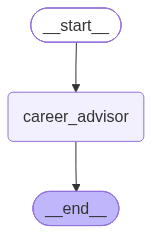

In [10]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [11]:
result = graph.invoke({
    "strength": 9,
    "agility": 7,
    "intelligence": 3
})

print(result["class_name"])

🛡️ 坦克战士
